# Correcting performance claims for multiple testing

A one-sided test turns every per-period Sharpe estimate into a probability under the zero-Sharpe null:

$$
z_j=\widehat{SR}_j\sqrt{T},
\qquad
p_j=1-\Phi(z_j).
$$

Here, $\widehat{SR}_j$ is the Sharpe ratio for trial $j$, $T$ is its number of returns, $z_j$ is the standardized statistic under the independent normal null, $\Phi$ is the standard-normal distribution function, and $p_j$ is the one-sided p-value for a positive Sharpe ratio.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import hashlib
import math
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as ss
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset

from RiskLabAI.backtest.probabilistic_sharpe_ratio import benchmark_sharpe_ratio, probabilistic_sharpe_ratio
from RiskLabAI.backtest.sharpe_inference import lplz_sharpe_inference, newey_west_automatic_lag, newey_west_long_run_variance, sharpe_ratio_influence_function
from RiskLabAI.backtest.multiple_testing import benjamini_hochberg_yekutieli_adjusted_p_values, haircut_sharpe_ratios, holm_adjusted_p_values, sharpe_ratio_p_values
from RiskLabAI.backtest.test_set_overfitting import expected_max_sharpe_ratio, estimated_sharpe_ratio_z_statistics, strategy_type1_error_probability, strategy_type2_error_probability, theta_for_type2_error
from RiskLabAI.backtest.robust_statistics import sharpe_difference_test

DATA_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
DATA_DIR = ROOT / "data" / "public" / "fred"
DATA_PATH = ensure_dataset(ROOT, "fred_sp500")
EXPECTED_DATA_HASH = "2098B209EE3AFDB3B2C1E783AC90A2BB7DD3865FEB416D0FABEDBB4A7A542754"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
raw = pd.read_csv(DATA_PATH)
raw["observation_date"] = pd.to_datetime(raw["observation_date"])
prices = raw.set_index("observation_date")["SP500"].dropna().astype(float).sort_index()
log_returns = np.log(prices).diff()

fast_windows = [3, 5, 10, 20]
slow_windows = [30, 60, 120, 240]
performance_columns = {}
catalog_rows = []
for fast_window in fast_windows:
    for slow_window in slow_windows:
        fast_average = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow_average = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
        trend_position = np.sign(fast_average - slow_average).replace(0, np.nan).ffill().shift(1)
        for orientation, multiplier in [("Trend", 1.0), ("Reversal", -1.0)]:
            name = f"{orientation} {fast_window}/{slow_window}"
            performance_columns[name] = multiplier * trend_position * log_returns
            catalog_rows.append({"Trial": len(catalog_rows) + 1, "Rule": orientation, "Fast span": fast_window, "Slow span": slow_window, "Name": name})
performances = pd.DataFrame(performance_columns).dropna()
strategy_catalog = pd.DataFrame(catalog_rows)

FIGURES = ROOT / "outputs" / "figures" / "20_sharpe_multiple_testing"
TABLES = ROOT / "outputs" / "tables" / "20_sharpe_multiple_testing"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("-inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def period_sharpe(values):
    array = np.asarray(values, dtype=float)
    deviation = array.std(ddof=1)
    return float(array.mean() / deviation) if deviation > 0 else 0.0

def return_moments(values):
    array = np.asarray(values, dtype=float)
    return float(ss.skew(array, bias=False)), float(ss.kurtosis(array, fisher=False, bias=False))

def opposite_name(name):
    return name.replace("Trend", "Reversal") if name.startswith("Trend") else name.replace("Reversal", "Trend")

trial_sharpes = np.array([period_sharpe(performances[column]) for column in performances])
annual_sharpes = trial_sharpes * np.sqrt(252.0)
trial_mean = float(trial_sharpes.mean())
trial_spread = float(trial_sharpes.std(ddof=0))
trial_count = performances.shape[1]
observation_count = performances.shape[0]
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Trial Family Corrections

Holm's ordered correction increases each raw p-value according to the number of hypotheses that remain:

$$
p_{(i)}^{Holm}=\min\!\left\{1,\max_{1\leq j\leq i}(M-j+1)p_{(j)}\right\}.
$$

Here, $M$ is the number of tested trials, $p_{(j)}$ is the $j$th smallest raw p-value, $i$ is its ordered position, and $p_{(i)}^{Holm}$ is the adjusted p-value that controls the chance of at least one false rejection across the family.

The Benjamini-Hochberg-Yekutieli correction uses a harmonic dependence factor and works backward through the ordered p-values:

$$
c_M=\sum_{j=1}^{M}\frac{1}{j},
\qquad
p_{(i)}^{BHY}=\min\!\left\{1,\min_{i\leq j\leq M}\frac{c_M M}{j}p_{(j)}\right\}.
$$

Here, $c_M$ is the harmonic dependence factor, $M$ is the family size, $p_{(j)}$ is the $j$th ordered raw p-value, and $p_{(i)}^{BHY}$ is the adjusted p-value that controls the expected fraction of false discoveries under arbitrary dependence.

An adjusted p-value can be expressed on the same scale as the original per-period Sharpe ratio:

$$
\widehat{SR}_{j,adj}=\frac{\Phi^{-1}(1-p_{j,adj})}{\sqrt{T}}.
$$

Here, $p_{j,adj}$ is the adjusted p-value for trial $j$, $\Phi^{-1}$ is the standard-normal quantile function, $T$ is the number of returns, and $\widehat{SR}_{j,adj}$ is the Sharpe ratio implied by that adjusted probability.

,Trial,Name,Annual Sharpe,Raw p-value,Holm p-value,BHY p-value,Holm haircut Sharpe,BHY haircut Sharpe,Holm discovery,BHY discovery
0,1,Trend 3/30,0.368432,0.144336,1,1,-inf,-inf,False,False
1,2,Reversal 3/30,-0.368432,0.855664,1,1,-inf,-inf,False,False
2,3,Trend 3/60,0.252547,0.233521,1,1,-inf,-inf,False,False
3,4,Reversal 3/60,-0.252547,0.766479,1,1,-inf,-inf,False,False
4,5,Trend 3/120,0.290021,0.201796,1,1,-inf,-inf,False,False
5,6,Reversal 3/120,-0.290021,0.798204,1,1,-inf,-inf,False,False
6,7,Trend 3/240,0.199220,0.283076,1,1,-inf,-inf,False,False
7,8,Reversal 3/240,-0.199220,0.716924,1,1,-inf,-inf,False,False
8,9,Trend 5/30,0.448622,0.098183,1,1,-inf,-inf,False,False
9,10,Reversal 5/30,-0.448622,0.901817,1,1,-inf,-inf,False,False


,Trial,Name,Annual Sharpe,Raw p-value,Holm p-value,BHY p-value,Holm haircut Sharpe,BHY haircut Sharpe,Holm discovery,BHY discovery
8,9,Trend 5/30,0.448622,0.098183,1,1,-inf,-inf,False,False
26,27,Trend 20/60,0.413375,0.116931,1,1,-inf,-inf,False,False
12,13,Trend 5/120,0.370794,0.142797,1,1,-inf,-inf,False,False
0,1,Trend 3/30,0.368432,0.144336,1,1,-inf,-inf,False,False
20,21,Trend 10/120,0.356375,0.152372,1,1,-inf,-inf,False,False
16,17,Trend 10/30,0.342441,0.162021,1,1,-inf,-inf,False,False
4,5,Trend 3/120,0.290021,0.201796,1,1,-inf,-inf,False,False
2,3,Trend 3/60,0.252547,0.233521,1,1,-inf,-inf,False,False
14,15,Trend 5/240,0.250915,0.234962,1,1,-inf,-inf,False,False
18,19,Trend 10/60,0.216851,0.266149,1,1,-inf,-inf,False,False


,Procedure,Error target,Discoveries at five percent,Smallest p-value
0,No family correction,Individual one-sided error,0,0.098183
1,Holm,Chance of any false discovery,0,1
2,BHY,Expected false share among discoveries,0,1


,Quantity,Value
0,Trials,32
1,Pairwise correlations,496
2,Mean correlation,-0.032258
3,Mean absolute correlation,0.719366
4,Median absolute correlation,0.750579
5,Largest absolute correlation,1


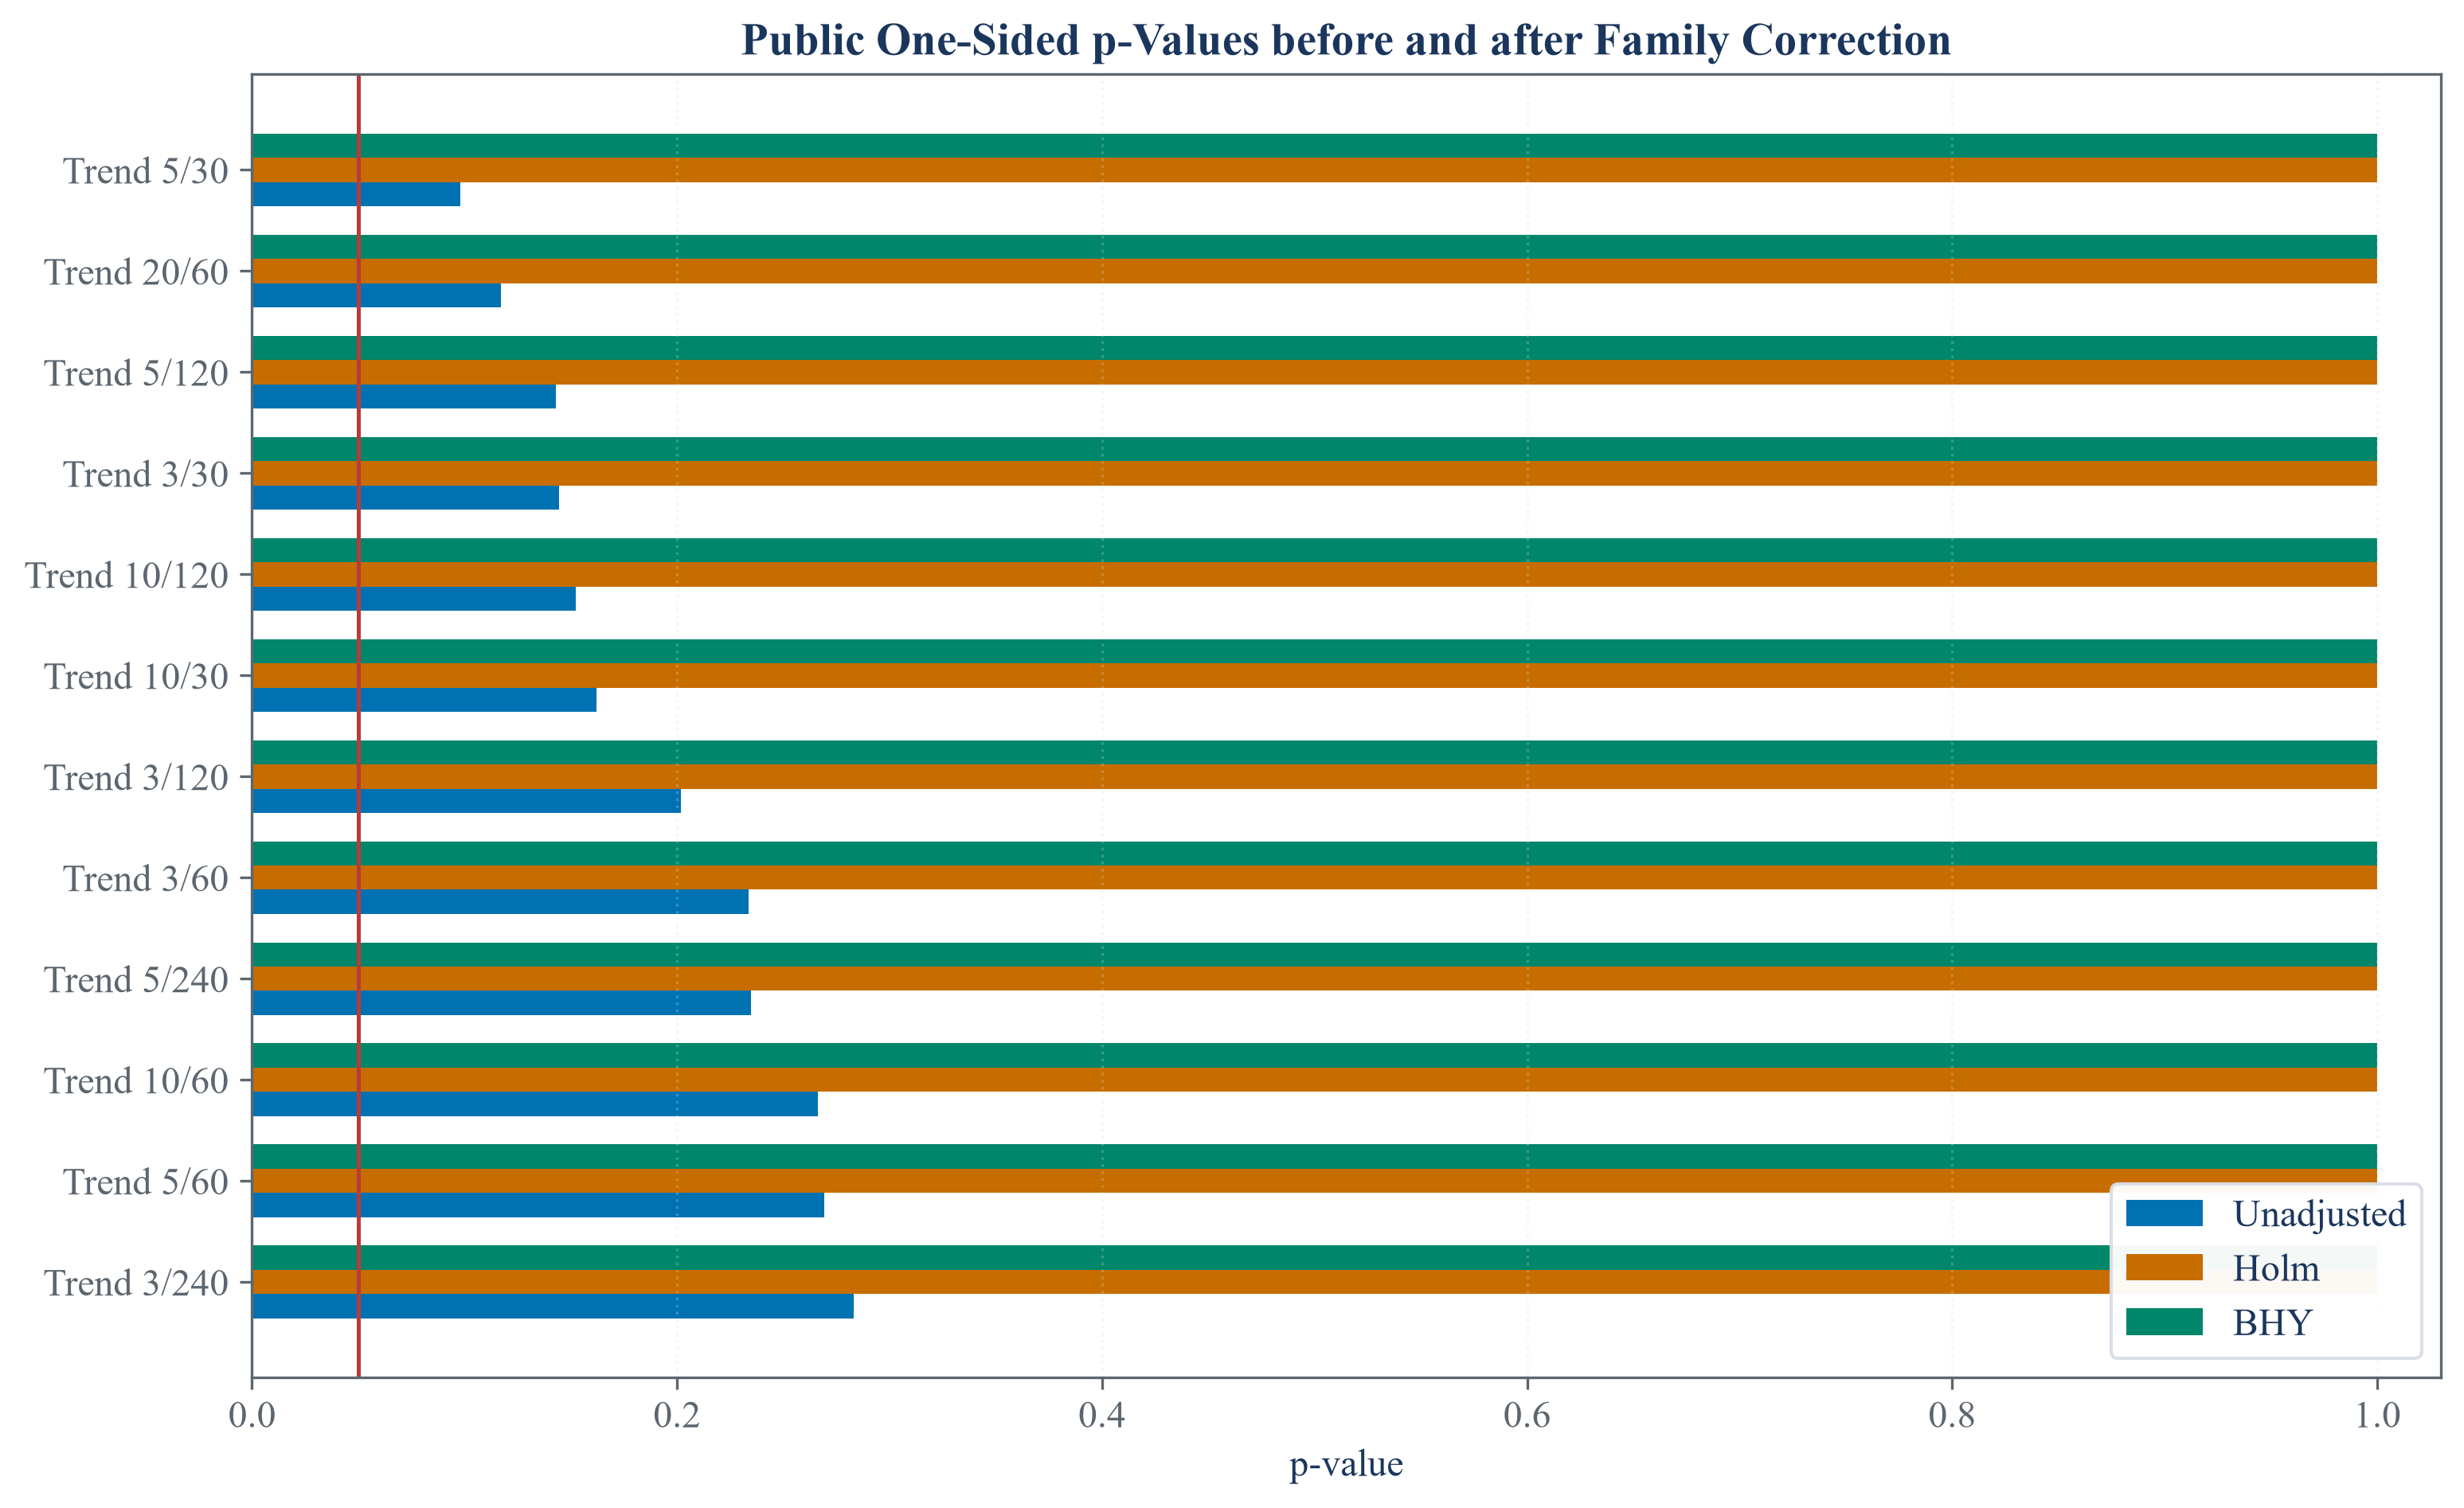

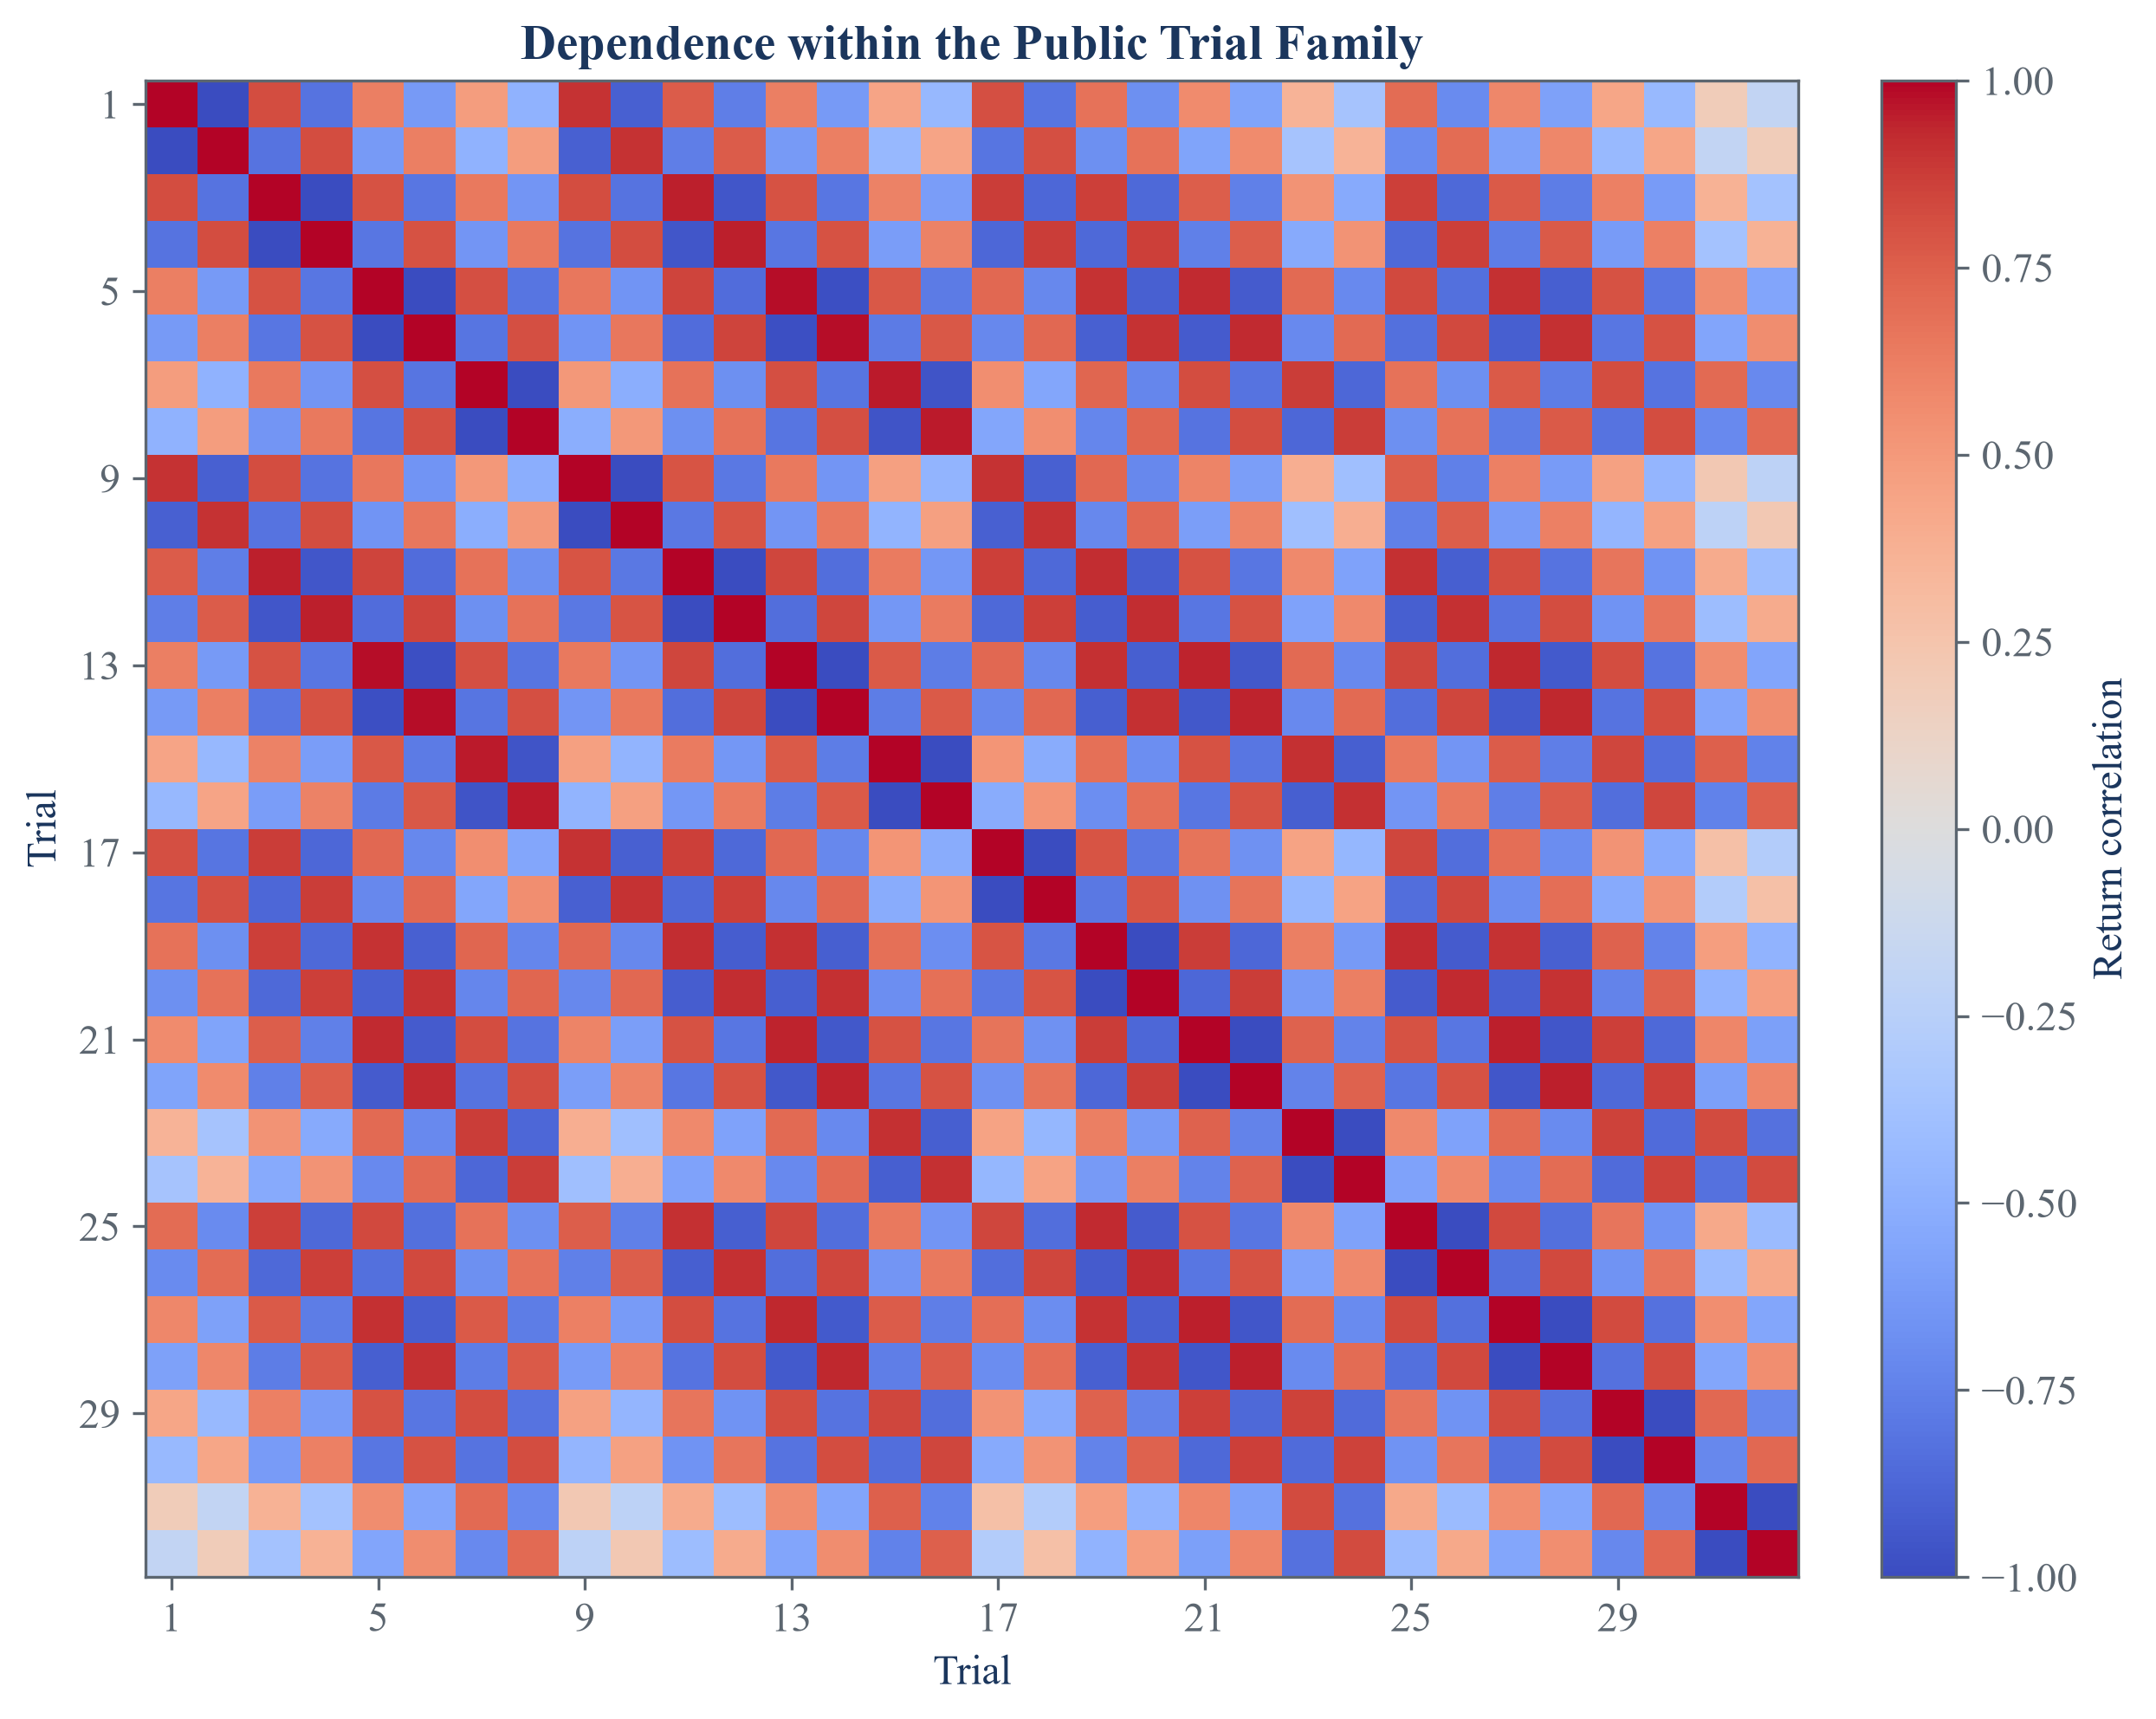

In [2]:
holm_public = haircut_sharpe_ratios(trial_sharpes, observation_count, method="holm")
bhy_public = haircut_sharpe_ratios(trial_sharpes, observation_count, method="bhy")
public_multiple_testing = pd.DataFrame({
    "Trial": np.arange(1, trial_count + 1),
    "Name": performances.columns,
    "Annual Sharpe": annual_sharpes,
    "Raw p-value": holm_public["p_values"],
    "Holm p-value": holm_public["adjusted_p_values"],
    "BHY p-value": bhy_public["adjusted_p_values"],
    "Holm haircut Sharpe": holm_public["haircut_sharpe_ratios"] * np.sqrt(252.0),
    "BHY haircut Sharpe": bhy_public["haircut_sharpe_ratios"] * np.sqrt(252.0),
    "Holm discovery": holm_public["significant"],
    "BHY discovery": bhy_public["significant"],
})
leading_public_multiple_testing = public_multiple_testing.sort_values(["Annual Sharpe", "Trial"], ascending=[False, True]).head(12)
procedure_summary = pd.DataFrame({
    "Procedure": ["No family correction", "Holm", "BHY"],
    "Error target": ["Individual one-sided error", "Chance of any false discovery", "Expected false share among discoveries"],
    "Discoveries at five percent": [(holm_public["p_values"] < 0.05).sum(), holm_public["significant"].sum(), bhy_public["significant"].sum()],
    "Smallest p-value": [holm_public["p_values"].min(), holm_public["adjusted_p_values"].min(), bhy_public["adjusted_p_values"].min()],
})
correlations = performances.corr()
upper_values = correlations.to_numpy()[np.triu_indices(trial_count, k=1)]
trial_dependence_summary = pd.DataFrame({"Quantity": ["Trials", "Pairwise correlations", "Mean correlation", "Mean absolute correlation", "Median absolute correlation", "Largest absolute correlation"], "Value": [trial_count, len(upper_values), upper_values.mean(), np.abs(upper_values).mean(), np.median(np.abs(upper_values)), np.abs(upper_values).max()]})
save_table(public_multiple_testing, "public_multiple_testing", "Multiple-testing results for every public trial.", "tab:chapter18-public-multiple-all")
save_table(leading_public_multiple_testing, "leading_public_multiple_testing", "Sharpe haircuts for the twelve largest public Sharpe estimates.", "tab:chapter18-leading-haircuts")
save_table(procedure_summary, "procedure_summary", "Discoveries in the public trial family under three error rules.", "tab:chapter18-procedure-summary")
save_table(trial_dependence_summary, "trial_dependence_summary", "Dependence among the public strategy trials.", "tab:chapter18-trial-dependence", fit=False)
display(public_multiple_testing)
display(leading_public_multiple_testing)
display(procedure_summary)
display(trial_dependence_summary)

ordered = leading_public_multiple_testing.sort_values("Annual Sharpe")
y = np.arange(len(ordered))
figure, axis = plt.subplots(figsize=(10.2, 6.2), constrained_layout=True)
axis.barh(y - 0.24, ordered["Raw p-value"], height=0.24, color=palette["cyan"], label="Unadjusted")
axis.barh(y, ordered["Holm p-value"], height=0.24, color=palette["amber"], label="Holm")
axis.barh(y + 0.24, ordered["BHY p-value"], height=0.24, color=palette["green"], label="BHY")
axis.set_yticks(y, ordered["Name"])
axis.axvline(0.05, color=palette["rose"], linewidth=1.2)
axis.set_title("Public One-Sided p-Values before and after Family Correction")
axis.set_xlabel("p-value")
axis.set_xlim(0, 1.03)
axis.legend()
axis.grid(axis="x", alpha=0.25)
figure.savefig(FIGURES / "public_haircuts.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_haircuts.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_haircuts.png")))
plt.close(figure)

figure, axis = plt.subplots(figsize=(8.2, 6.5), constrained_layout=True)
image = axis.imshow(correlations.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
axis.set_title("Dependence within the Public Trial Family")
axis.set_xlabel("Trial")
axis.set_ylabel("Trial")
ticks = np.arange(0, trial_count, 4)
axis.set_xticks(ticks, ticks + 1)
axis.set_yticks(ticks, ticks + 1)
figure.colorbar(image, ax=axis, label="Return correlation")
figure.savefig(FIGURES / "trial_correlation.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "trial_correlation.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "trial_correlation.png")))
plt.close(figure)

## Preliminary Planted-Edge Reproduction

,Trial,Known edge,Raw Sharpe,Holm p-value,Holm haircut Sharpe,Holm discovery,BHY p-value,BHY haircut Sharpe,BHY discovery
0,2,True,0.389464,0.000199,0.323323,True,0.000715,0.291078,True
1,1,True,0.355244,0.000946,0.283588,True,0.001792,0.265884,True
2,0,True,0.245720,0.063974,0.138961,False,0.085245,0.125121,False
3,4,False,0.155232,0.756839,-0.063551,False,0.800855,-0.077108,False
4,17,False,0.138730,1,-inf,False,0.901942,-0.118006,False
5,10,False,0.131276,1,-inf,False,0.901942,-0.118006,False
6,13,False,0.109598,1,-inf,False,1,-inf,False
7,3,False,0.083906,1,-inf,False,1,-inf,False


,Quantity,Value
0,Returns,120
1,Trials,20
2,Known positive trials,3
3,Largest raw Sharpe,0.389464
4,Second-largest raw Sharpe,0.355244
5,Expected maximum for one trial,0
6,Expected maximum for five trials,0.158703
7,Expected maximum for twenty trials,0.252934
8,Holm discoveries,2
9,BHY discoveries,2


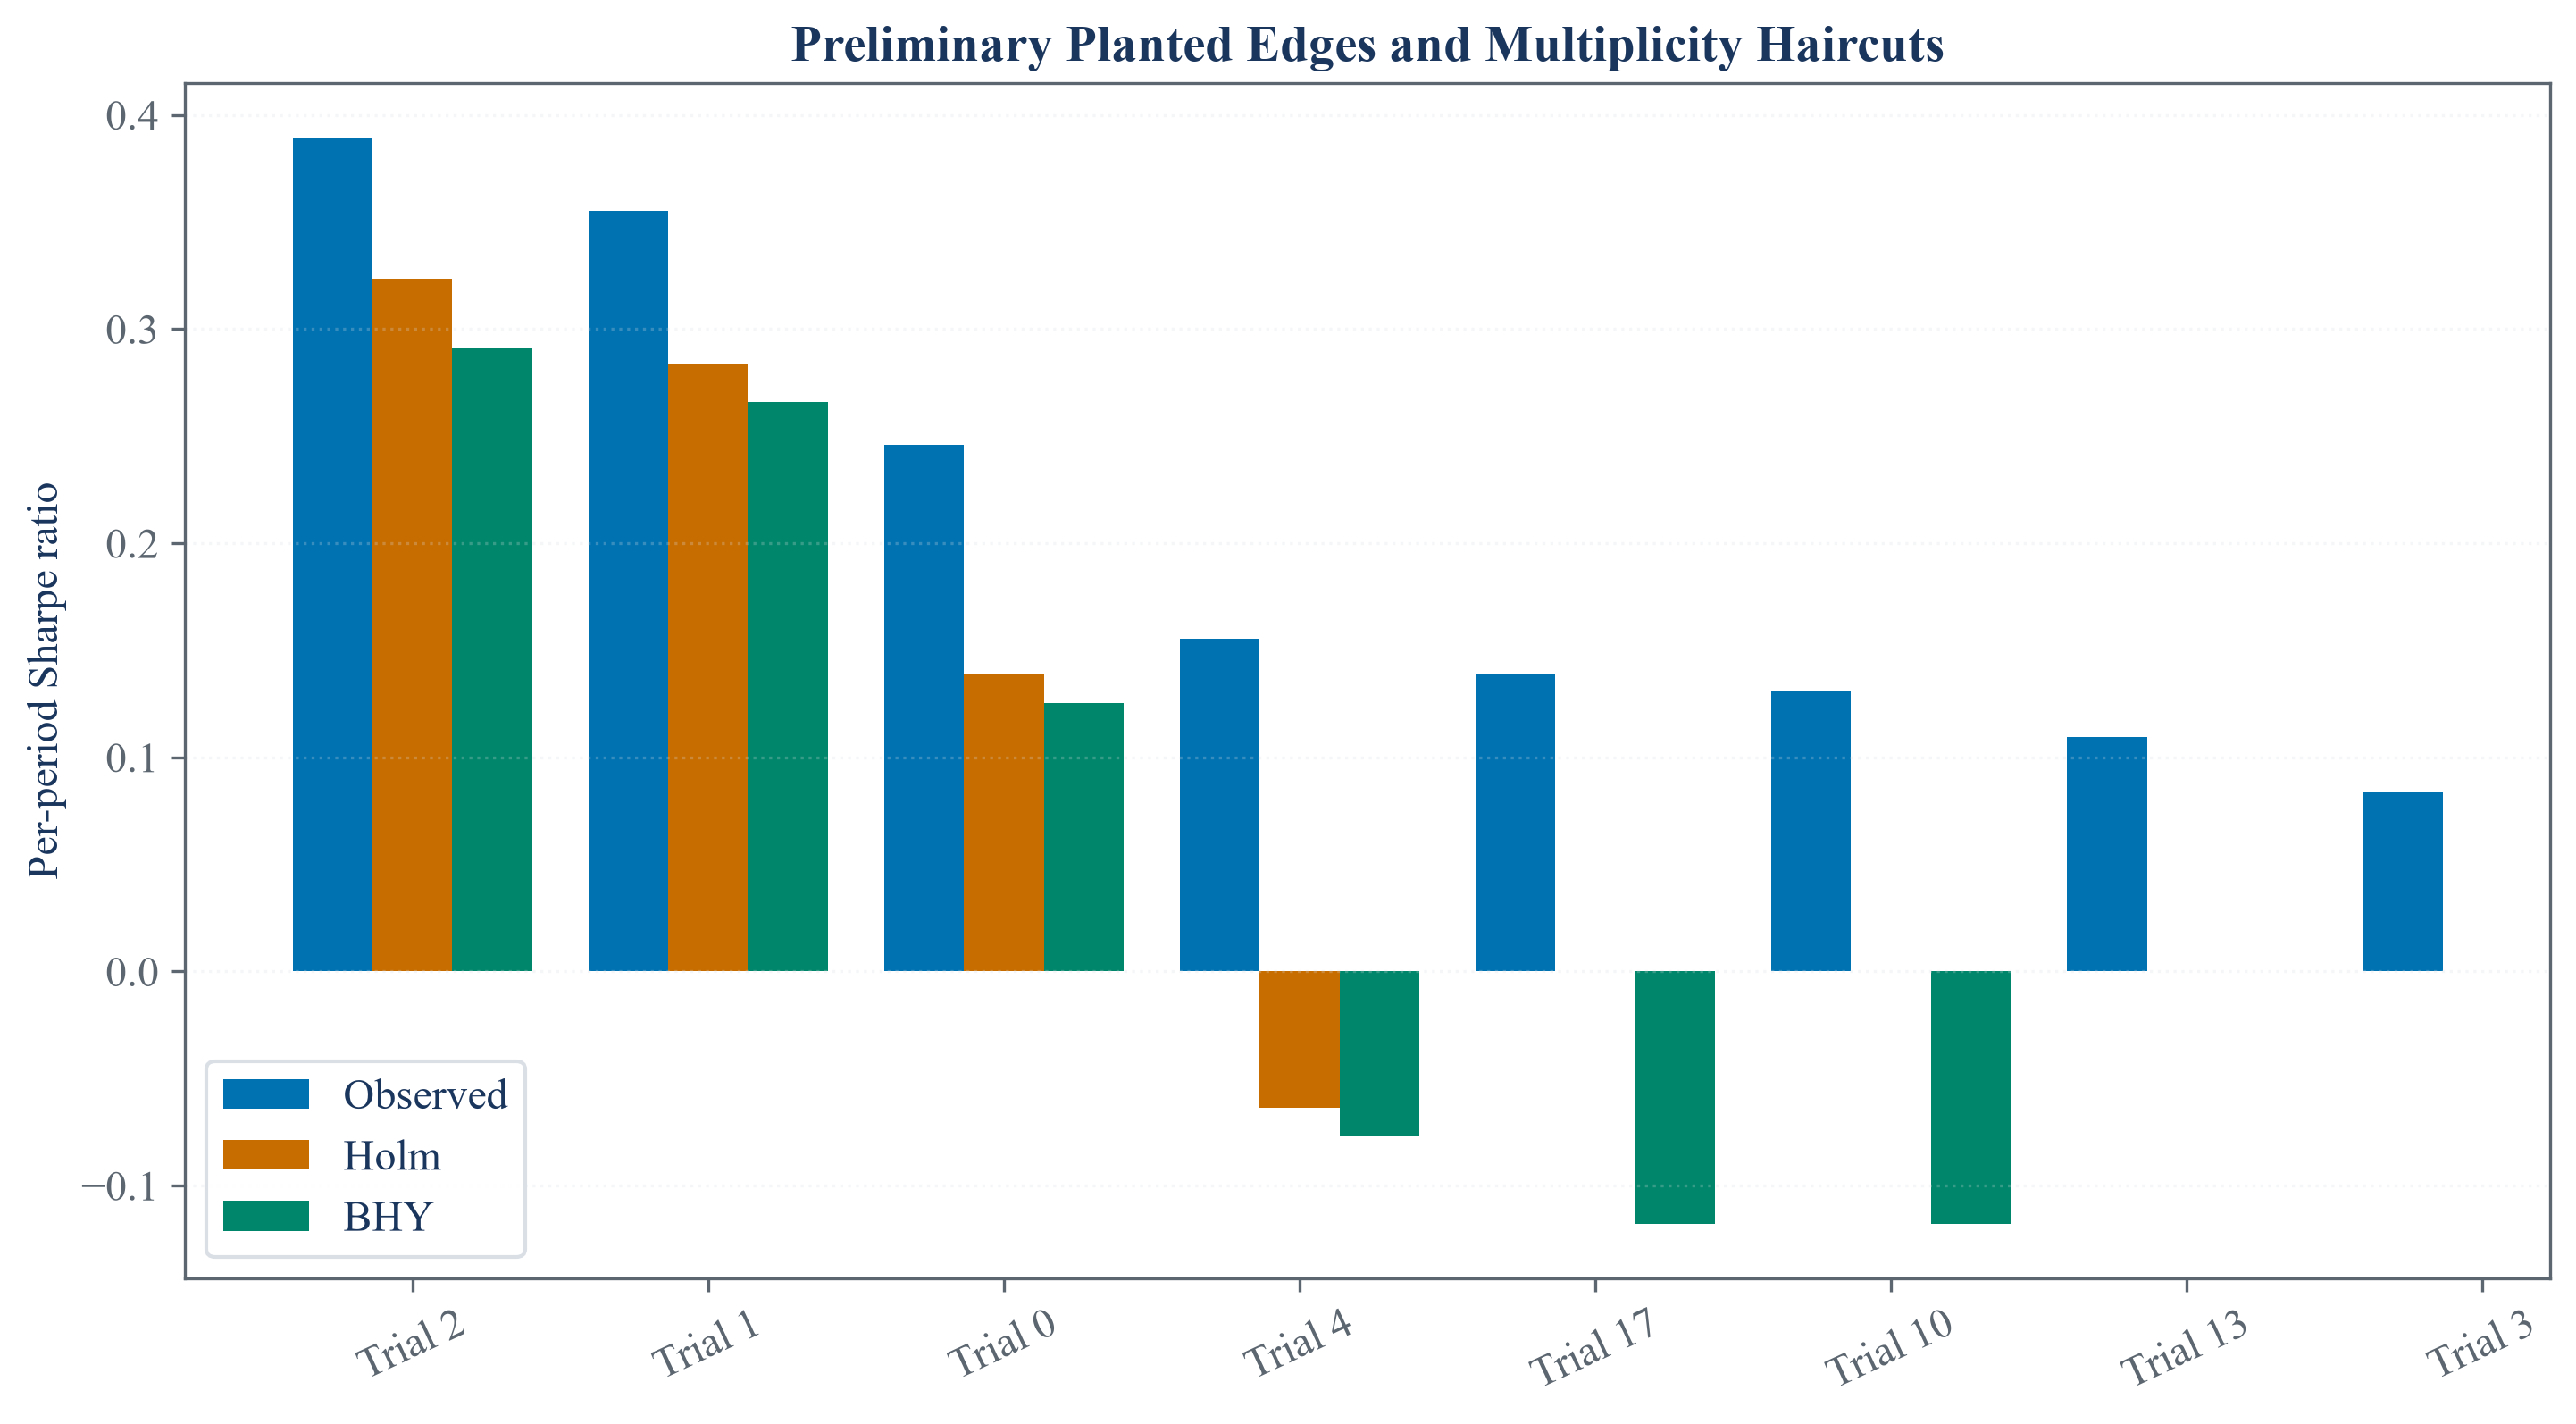

In [3]:
preliminary_rng = np.random.default_rng(3)
preliminary_returns = []
for trial in range(20):
    mean_return = 0.012 if trial < 3 else 0.0
    preliminary_returns.append(preliminary_rng.standard_normal(120) * 0.04 + mean_return)
preliminary_sharpes = np.array([period_sharpe(values) for values in preliminary_returns])
preliminary_order = np.argsort(preliminary_sharpes)[::-1]
preliminary_holm = haircut_sharpe_ratios(preliminary_sharpes, 120, method="holm")
preliminary_bhy = haircut_sharpe_ratios(preliminary_sharpes, 120, method="bhy")
preliminary_planted_edges = pd.DataFrame({
    "Trial": preliminary_order[:8],
    "Known edge": preliminary_order[:8] < 3,
    "Raw Sharpe": preliminary_sharpes[preliminary_order[:8]],
    "Holm p-value": preliminary_holm["adjusted_p_values"][preliminary_order[:8]],
    "Holm haircut Sharpe": preliminary_holm["haircut_sharpe_ratios"][preliminary_order[:8]],
    "Holm discovery": preliminary_holm["significant"][preliminary_order[:8]],
    "BHY p-value": preliminary_bhy["adjusted_p_values"][preliminary_order[:8]],
    "BHY haircut Sharpe": preliminary_bhy["haircut_sharpe_ratios"][preliminary_order[:8]],
    "BHY discovery": preliminary_bhy["significant"][preliminary_order[:8]],
})
preliminary_spread = preliminary_sharpes.std(ddof=0)
preliminary_haircut_summary = pd.DataFrame({
    "Quantity": ["Returns", "Trials", "Known positive trials", "Largest raw Sharpe", "Second-largest raw Sharpe", "Expected maximum for one trial", "Expected maximum for five trials", "Expected maximum for twenty trials", "Holm discoveries", "BHY discoveries"],
    "Value": [120, 20, 3, preliminary_sharpes[preliminary_order[0]], preliminary_sharpes[preliminary_order[1]], expected_max_sharpe_ratio(1, 0.0, preliminary_spread), expected_max_sharpe_ratio(5, 0.0, preliminary_spread), expected_max_sharpe_ratio(20, 0.0, preliminary_spread), preliminary_holm["significant"].sum(), preliminary_bhy["significant"].sum()],
})
save_table(preliminary_planted_edges, "preliminary_planted_edges", "The eight largest Sharpe ratios in the preliminary planted-edge experiment.", "tab:chapter18-preliminary-planted")
save_table(preliminary_haircut_summary, "preliminary_haircut_summary", "Summary of the preliminary planted-edge and haircut calculations.", "tab:chapter18-preliminary-haircut", fit=False)
display(preliminary_planted_edges)
display(preliminary_haircut_summary)

x = np.arange(len(preliminary_planted_edges))
preliminary_plot_edges = preliminary_planted_edges.replace([np.inf, -np.inf], np.nan)
figure, axis = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
axis.bar(x - 0.27, preliminary_planted_edges["Raw Sharpe"], width=0.27, color=palette["cyan"], label="Observed")
axis.bar(x, preliminary_plot_edges["Holm haircut Sharpe"], width=0.27, color=palette["amber"], label="Holm")
axis.bar(x + 0.27, preliminary_plot_edges["BHY haircut Sharpe"], width=0.27, color=palette["green"], label="BHY")
axis.set_xticks(x, [f"Trial {value}" for value in preliminary_planted_edges["Trial"]], rotation=25)
axis.set_title("Preliminary Planted Edges and Multiplicity Haircuts")
axis.set_ylabel("Per-period Sharpe ratio")
axis.legend()
axis.grid(axis="y", alpha=0.25)
figure.savefig(FIGURES / "preliminary_haircuts.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "preliminary_haircuts.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "preliminary_haircuts.png")))
plt.close(figure)

Without a family correction, independent tests make at least one false rejection with probability:

$$
\alpha_M=1-(1-\alpha)^M.
$$

Here, $\alpha$ is the false-positive probability for one test, $M$ is the number of independent tests, and $\alpha_M$ is the probability of at least one false positive across the family.

## Understanding the cost of error control

,Tests,Individual error rate,Family error rate
0,1,0.05,0.050000
1,5,0.05,0.226219
2,10,0.05,0.401263
3,20,0.05,0.641514
4,50,0.05,0.923055
5,100,0.05,0.994079


,Returns,Trials,True positive trials,Procedure,Family false-positive rate,False discovery rate,True discovery rate,Repetitions
0,120,5,3,Unadjusted,0.075,0.027917,0.711667,200
1,120,5,3,Holm,0.045,0.023333,0.485000,200
2,120,5,3,BHY,0.020,0.007500,0.418333,200
3,120,20,3,Unadjusted,0.595,0.256333,0.706667,200
4,120,20,3,Holm,0.045,0.030000,0.310000,200
5,120,20,3,BHY,0.030,0.015000,0.218333,200
6,120,50,3,Unadjusted,0.890,0.488147,0.711667,200
7,120,50,3,Holm,0.055,0.042500,0.230000,200
8,120,50,3,BHY,0.025,0.015833,0.140000,200
9,500,5,3,Unadjusted,0.100,0.025750,0.998333,200


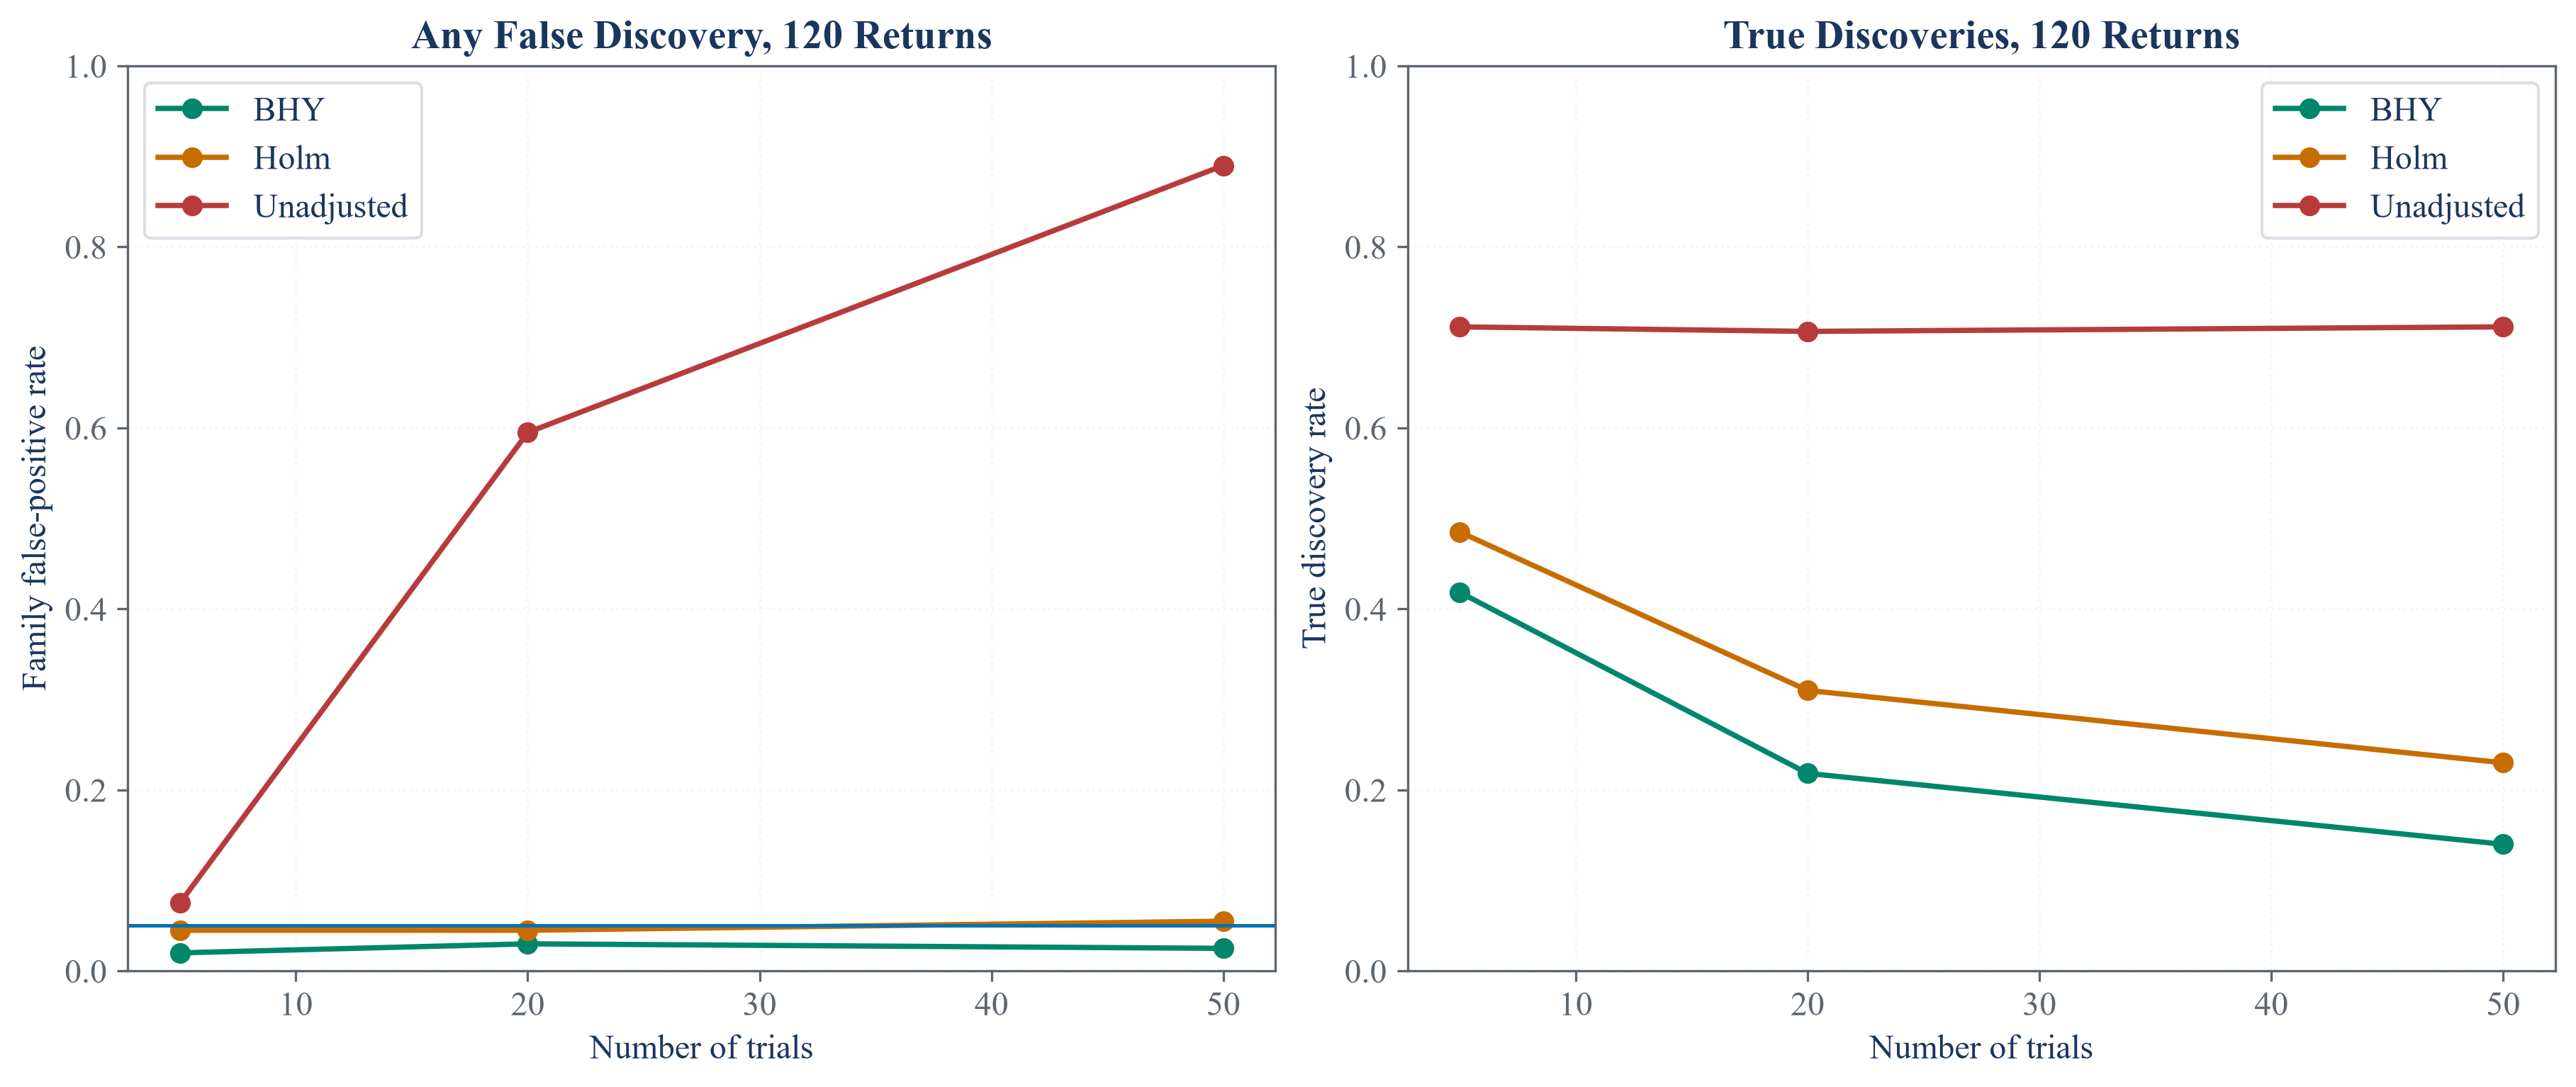

In [4]:
type1_error_growth = pd.DataFrame({"Tests": [1, 5, 10, 20, 50, 100], "Individual error rate": [0.05] * 6, "Family error rate": [1.0 - 0.95**count for count in [1, 5, 10, 20, 50, 100]]})
simulation_rows = []
for number_of_returns in [120, 500]:
    for number_of_trials in [5, 20, 50]:
        method_records = {name: {"false_family": [], "false_share": [], "true_share": []} for name in ["Unadjusted", "Holm", "BHY"]}
        true_count = min(3, number_of_trials)
        for repetition in range(200):
            rng = np.random.default_rng(500000 + 10000 * number_of_returns + 100 * number_of_trials + repetition)
            values = rng.standard_normal((number_of_returns, number_of_trials)) * 0.04
            values[:, :true_count] += 0.008
            sharpes = values.mean(axis=0) / values.std(axis=0, ddof=1)
            raw_p = sharpe_ratio_p_values(sharpes, number_of_returns)
            decisions = {
                "Unadjusted": raw_p < 0.05,
                "Holm": holm_adjusted_p_values(raw_p) < 0.05,
                "BHY": benjamini_hochberg_yekutieli_adjusted_p_values(raw_p) < 0.05,
            }
            for method, selected in decisions.items():
                false_count = int(selected[true_count:].sum())
                discovery_count = int(selected.sum())
                method_records[method]["false_family"].append(int(false_count > 0))
                method_records[method]["false_share"].append(false_count / max(discovery_count, 1))
                method_records[method]["true_share"].append(float(selected[:true_count].mean()))
        for method, record in method_records.items():
            simulation_rows.append({"Returns": number_of_returns, "Trials": number_of_trials, "True positive trials": true_count, "Procedure": method, "Family false-positive rate": np.mean(record["false_family"]), "False discovery rate": np.mean(record["false_share"]), "True discovery rate": np.mean(record["true_share"]), "Repetitions": 200})
controlled_error_rates = pd.DataFrame(simulation_rows)
save_table(type1_error_growth, "type1_error_growth", "Growth in the chance of at least one false positive without correction.", "tab:chapter18-type1-growth", fit=False)
save_table(controlled_error_rates, "controlled_error_rates", "Controlled false discoveries and power as sample and family sizes change.", "tab:chapter18-controlled-error-rates")
display(type1_error_growth)
display(controlled_error_rates)

figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
colors = {"Unadjusted": palette["rose"], "Holm": palette["amber"], "BHY": palette["green"]}
for method, group in controlled_error_rates[controlled_error_rates["Returns"] == 120].groupby("Procedure"):
    axes[0].plot(group["Trials"], group["Family false-positive rate"], marker="o", linewidth=1.8, color=colors[method], label=method)
    axes[1].plot(group["Trials"], group["True discovery rate"], marker="o", linewidth=1.8, color=colors[method], label=method)
axes[0].axhline(0.05, color=palette["cyan"], linewidth=1.2)
axes[0].set_title("Any False Discovery, 120 Returns")
axes[0].set_xlabel("Number of trials")
axes[0].set_ylabel("Family false-positive rate")
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].set_title("True Discoveries, 120 Returns")
axes[1].set_xlabel("Number of trials")
axes[1].set_ylabel("True discovery rate")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.25)
figure.savefig(FIGURES / "controlled_error_rates.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "controlled_error_rates.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "controlled_error_rates.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == EXPECTED_DATA_HASH
assert observation_count == 2090
assert trial_count == 32
assert public_multiple_testing.shape == (32, 10)
assert leading_public_multiple_testing.shape == (12, 10)
assert procedure_summary.shape == (3, 4)
assert trial_dependence_summary.shape == (6, 2)
assert public_multiple_testing[["Raw p-value", "Holm p-value", "BHY p-value"]].apply(lambda column: column.between(0, 1).all()).all()
assert (public_multiple_testing["Holm p-value"] >= public_multiple_testing["Raw p-value"] - 1e-15).all()
assert (public_multiple_testing["BHY p-value"] >= public_multiple_testing["Raw p-value"] - 1e-15).all()
assert preliminary_sharpes.shape == (20,)
assert preliminary_order[:3].tolist() == [2, 1, 0]
assert np.allclose(preliminary_sharpes[preliminary_order[:3]], [0.38946401, 0.35524443, 0.24572023], atol=1e-8)
assert preliminary_holm["significant"].sum() == 2
assert preliminary_bhy["significant"].sum() == 2
assert np.isclose(preliminary_holm["haircut_sharpe_ratios"][preliminary_order[0]], 0.3233229568994212)
assert np.isclose(preliminary_bhy["haircut_sharpe_ratios"][preliminary_order[0]], 0.291078175760912)
assert np.allclose([expected_max_sharpe_ratio(count, 0.0, preliminary_spread) for count in [1, 5, 20]], [0.0, 0.1587026354881373, 0.252933823991373])
assert type1_error_growth.shape == (6, 3)
assert np.allclose(type1_error_growth["Family error rate"], [strategy_type1_error_probability(ss.norm.ppf(0.95), int(count)) for count in type1_error_growth["Tests"]])
assert controlled_error_rates.shape == (18, 8)
assert controlled_error_rates[["Family false-positive rate", "False discovery rate", "True discovery rate"]].apply(lambda column: column.between(0, 1).all()).all()
assert controlled_error_rates["Repetitions"].eq(200).all()
theta = theta_for_type2_error(0.2, 120, 0.2)
assert 0 < strategy_type2_error_probability(0.05, 20, theta) < 1
assert (FIGURES / "public_haircuts.pdf").is_file()
assert (FIGURES / "trial_correlation.pdf").is_file()
assert (FIGURES / "preliminary_haircuts.pdf").is_file()
assert (FIGURES / "controlled_error_rates.pdf").is_file()
assert (TABLES / "public_multiple_testing.tex").is_file()
assert (TABLES / "leading_public_multiple_testing.tex").is_file()
assert (TABLES / "procedure_summary.tex").is_file()
assert (TABLES / "trial_dependence_summary.tex").is_file()
assert (TABLES / "preliminary_planted_edges.tex").is_file()
assert (TABLES / "preliminary_haircut_summary.tex").is_file()
assert (TABLES / "type1_error_growth.tex").is_file()
assert (TABLES / "controlled_error_rates.tex").is_file()